# Decentralized Hiking AI
## 02 - Knuckles Trail Preprocessing and Feature Engineering

**Research Component:** Context-Aware Offline Resource Recommendation

### Objective

This notebook preprocesses the real Knuckles trail and terrain datasets
to construct a reliable trail-level feature table for machine-learning
development.

The preprocessing pipeline will:

- load the 559 OpenStreetMap candidate trail/path geometries;
- preserve the original OSM identifiers and relevant trail attributes;
- remove or exclude unsuitable records only when supported by evidence;
- integrate Copernicus DEM-derived elevation information;
- derive terrain characteristics from point-level elevation profiles;
- calculate representative geographic locations for each candidate path;
- derive emergency/support facility proximity features;
- derive communication-infrastructure proximity features as connectivity proxies;
- prepare the trail-level data for later integration with historical weather context.

### Data Integrity Policy

Only real collected data and transparently derived features are used.

No synthetic or mock observations are introduced.

Missing OpenStreetMap attributes will not be replaced with fabricated values.

Communication structures are treated only as geographic connectivity/remoteness
proxies and are not interpreted as verified mobile network coverage.

### Expected Output

The final output of this notebook will be a clean trail-level feature dataset
containing variables such as:

- trail identifier;
- path type;
- trail length;
- representative latitude and longitude;
- minimum and maximum elevation;
- elevation range;
- elevation gain and loss;
- slope characteristics;
- proximity to emergency/support facilities;
- proximity to mapped communication infrastructure.

Historical weather features and recommendation target labels will be handled
in later stages of the research pipeline.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

current = Path.cwd().resolve()

if current.name == "notebooks":
    PROJECT_ROOT = current.parent.parent
elif (current / "research").exists():
    PROJECT_ROOT = current
else:
    raise FileNotFoundError(
        f"Could not locate project root from: {current}"
    )

# ------------------------------------------------------------
# Research directories
# ------------------------------------------------------------

RESEARCH_DIR = PROJECT_ROOT / "research"
DATASET_DIR = RESEARCH_DIR / "dataset"

RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"

RESULTS_DIR = RESEARCH_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Verify setup
# ------------------------------------------------------------

print("Environment initialized successfully.")
print()
print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("Raw data     :", RAW_DIR)
print("Processed    :", PROCESSED_DIR)
print("Results      :", RESULTS_DIR)

print()
print("Dataset exists:", DATASET_DIR.exists())

Environment initialized successfully.

Project root : /Users/mirshad/Desktop/Decentralized-Hiking-AI
Dataset      : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset
Raw data     : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/raw
Processed    : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed
Results      : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/results

Dataset exists: True


In [2]:
trail_file = (
    PROCESSED_DIR
    / "trails"
    / "knuckles_candidate_paths.geojson"
)

print("Trail file exists:", trail_file.exists())

if not trail_file.exists():
    raise FileNotFoundError(
        f"Trail dataset not found: {trail_file}"
    )

trails = gpd.read_file(trail_file)

print("\nCandidate paths loaded successfully.")
print("Rows:", len(trails))
print("Columns:", len(trails.columns))
print("CRS:", trails.crs)

print("\nGeometry types:")
print(trails.geometry.geom_type.value_counts())

trails.head()

Trail file exists: True

Candidate paths loaded successfully.
Rows: 559
Columns: 38
CRS: EPSG:4326

Geometry types:
LineString    559
Name: count, dtype: int64


,id,osm_type,osm_id,tags,access,bicycle,bridge,crossing,crossing:markings,cutting,...,sac_scale,smoothness,surface,tracktype,wheelchair,width,verified_hiking_trail,length_km,hiking_relation_ids,geometry
0,way/100146710,way,100146710,"{ ""highway"": ""footway"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,1.654853,[ ],"LINESTRING (80.71194 7.41703, 80.71188 7.4173,..."
1,way/100146711,way,100146711,"{ ""highway"": ""track"", ""maxspeed"": ""25"", ""motor...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,4.966901,[ ],"LINESTRING (80.69633 7.42838, 80.6967 7.42826,..."
2,way/100146901,way,100146901,"{ ""highway"": ""path"", ""note"": ""Only for Mountai...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.859729,[ ],"LINESTRING (80.71186 7.43304, 80.71182 7.43317..."
3,way/100148512,way,100148512,"{ ""highway"": ""track"", ""maxspeed"": ""10"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.995269,[ ],"LINESTRING (80.71059 7.42809, 80.71073 7.4281,..."
4,way/100149325,way,100149325,"{ ""highway"": ""footway"", ""note"": ""Only for Moun...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.646777,[ ],"LINESTRING (80.71048 7.44174, 80.71058 7.44228..."


## 1. Candidate Trail Attribute Assessment

The OpenStreetMap dataset contains candidate paths rather than a fully
verified set of hiking trails.

Before preprocessing, the available OSM attributes are examined to determine
which variables are sufficiently populated and meaningful for the research.

No path is removed solely because optional OpenStreetMap attributes are
missing. Exclusion decisions will be based on explicit evidence such as
access restrictions or tags indicating that a path is unsuitable for hiking.

In [3]:
print("AVAILABLE TRAIL COLUMNS")
print("=" * 70)

for i, column in enumerate(trails.columns, start=1):
    print(f"{i:2}. {column}")

AVAILABLE TRAIL COLUMNS
 1. id
 2. osm_type
 3. osm_id
 4. tags
 5. access
 6. bicycle
 7. bridge
 8. crossing
 9. crossing:markings
10. cutting
11. description
12. embankment
13. foot
14. footway
15. highway
16. horse
17. incline
18. informal
19. lanes
20. layer
21. lit
22. maxspeed
23. motor_vehicle
24. motorcycle
25. mtb:scale
26. mtb:scale:uphill
27. name
28. note
29. sac_scale
30. smoothness
31. surface
32. tracktype
33. wheelchair
34. width
35. verified_hiking_trail
36. length_km
37. hiking_relation_ids
38. geometry


In [4]:
trail_missing = pd.DataFrame({
    "missing_count": trails.isna().sum(),
    "missing_percent": (
        trails.isna().mean() * 100
    ).round(2)
})

trail_missing = trail_missing.sort_values(
    "missing_percent",
    ascending=False
)

trail_missing

,missing_count,missing_percent
cutting,558,99.82
footway,558,99.82
sac_scale,558,99.82
mtb:scale,558,99.82
crossing,558,99.82
crossing:markings,558,99.82
lit,558,99.82
description,558,99.82
embankment,558,99.82
mtb:scale:uphill,558,99.82


In [5]:
important_trail_columns = [
    "highway",
    "access",
    "foot",
    "bicycle",
    "motor_vehicle",
    "surface",
    "tracktype",
    "smoothness",
    "sac_scale",
    "verified_hiking_trail"
]

for column in important_trail_columns:
    if column in trails.columns:
        print("\n" + "=" * 60)
        print(column.upper())
        print("=" * 60)

        print(
            trails[column]
            .value_counts(dropna=False)
            .head(30)
        )


HIGHWAY
highway
track        289
footway      125
path         124
steps         20
bridleway      1
Name: count, dtype: int64

ACCESS
access
None          551
no              4
permissive      3
permit          1
Name: count, dtype: int64

FOOT
foot
None      545
yes        12
permit      2
Name: count, dtype: int64

BICYCLE
bicycle
None    544
no       10
yes       5
Name: count, dtype: int64

MOTOR_VEHICLE
motor_vehicle
None    552
no        5
yes       2
Name: count, dtype: int64

SURFACE
surface
None               514
ground              15
concrete            11
unpaved              6
gravel               4
dirt                 2
paved                2
concrete:lanes       1
asphalt              1
rock                 1
mud                  1
concrete:plates      1
Name: count, dtype: int64

TRACKTYPE
tracktype
None      538
grade3      8
grade2      6
grade4      5
grade1      2
Name: count, dtype: int64

SMOOTHNESS
smoothness
None            552
very_bad          3
impassable 

In [6]:
# Convert OSM tag dictionaries to searchable text
tag_text = trails["tags"].astype(str).str.lower()

restriction_keywords = [
    "mountainbike",
    "mountain bike",
    "no pedestrians",
    "no pedestrian",
    "private",
    "foot=no",
    '"foot": "no"',
    "access=no",
    '"access": "no"'
]

potentially_unsuitable = pd.Series(
    False,
    index=trails.index
)

for keyword in restriction_keywords:
    potentially_unsuitable |= tag_text.str.contains(
        keyword,
        regex=False,
        na=False
    )

potentially_unsuitable_paths = trails.loc[
    potentially_unsuitable,
    [
        col for col in [
            "id",
            "highway",
            "name",
            "access",
            "foot",
            "bicycle",
            "length_km",
            "tags"
        ]
        if col in trails.columns
    ]
].copy()

print(
    "Potentially unsuitable/restricted records:",
    len(potentially_unsuitable_paths)
)

potentially_unsuitable_paths

Potentially unsuitable/restricted records: 6


,id,highway,name,access,foot,bicycle,length_km,tags
2,way/100146901,path,None,None,None,None,0.859729,"{ ""highway"": ""path"", ""note"": ""Only for Mountai..."
4,way/100149325,footway,None,None,None,None,0.646777,"{ ""highway"": ""footway"", ""note"": ""Only for Moun..."
31,way/249336982,path,None,no,yes,no,0.877428,"{ ""access"": ""no"", ""bicycle"": ""no"", ""foot"": ""ye..."
308,way/776284374,path,None,no,yes,None,0.972473,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""p..."
343,way/835238015,footway,Dawatagala - Knuckles 5 Peaks Nature Trail,no,permit,None,3.738512,"{ ""access"": ""no"", ""description"": ""This is a hi..."
502,way/1246011916,footway,None,no,yes,None,0.598044,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""f..."


In [7]:
pd.set_option("display.max_colwidth", None)

columns_to_show = [
    col for col in [
        "id",
        "highway",
        "name",
        "access",
        "foot",
        "bicycle",
        "motor_vehicle",
        "motorcycle",
        "note",
        "description",
        "verified_hiking_trail",
        "length_km",
        "tags"
    ]
    if col in trails.columns
]

potentially_unsuitable_paths[
    [
        col for col in columns_to_show
        if col in potentially_unsuitable_paths.columns
    ]
]

,id,highway,name,access,foot,bicycle,length_km,tags
2,way/100146901,path,None,None,None,None,0.859729,"{ ""highway"": ""path"", ""note"": ""Only for Mountainbikes"" }"
4,way/100149325,footway,None,None,None,None,0.646777,"{ ""highway"": ""footway"", ""note"": ""Only for Mountainbikes"" }"
31,way/249336982,path,None,no,yes,no,0.877428,"{ ""access"": ""no"", ""bicycle"": ""no"", ""foot"": ""yes"", ""highway"": ""path"", ""horse"": ""no"", ""informal"": ""yes"", ""maxspeed"": ""25"", ""motor_vehicle"": ""no"", ""motorcycle"": ""yes"" }"
308,way/776284374,path,None,no,yes,None,0.972473,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""path"", ""surface"": ""unpaved"" }"
343,way/835238015,footway,Dawatagala - Knuckles 5 Peaks Nature Trail,no,permit,None,3.738512,"{ ""access"": ""no"", ""description"": ""This is a hike of the 5 peaks that give the Knuckles Mountain Range their name. This is in the Knuckles Forest Conservation Area, and a permit from the Forest Department is required. The trail head shown as the ending location of the gps track is reachabl"", ""foot"": ""permit"", ""highway"": ""footway"", ""name"": ""Dawatagala - Knuckles 5 Peaks Nature Trail"", ""surface"": ""ground"", ""width"": ""0.5"" }"
502,way/1246011916,footway,None,no,yes,None,0.598044,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""footway"" }"


In [8]:
flagged_indices = potentially_unsuitable_paths.index

trails.loc[
    flagged_indices,
    columns_to_show
]

,id,highway,name,access,foot,bicycle,motor_vehicle,motorcycle,note,description,verified_hiking_trail,length_km,tags
2,way/100146901,path,None,None,None,None,None,None,Only for Mountainbikes,None,False,0.859729,"{ ""highway"": ""path"", ""note"": ""Only for Mountainbikes"" }"
4,way/100149325,footway,None,None,None,None,None,None,Only for Mountainbikes,None,False,0.646777,"{ ""highway"": ""footway"", ""note"": ""Only for Mountainbikes"" }"
31,way/249336982,path,None,no,yes,no,no,yes,None,None,False,0.877428,"{ ""access"": ""no"", ""bicycle"": ""no"", ""foot"": ""yes"", ""highway"": ""path"", ""horse"": ""no"", ""informal"": ""yes"", ""maxspeed"": ""25"", ""motor_vehicle"": ""no"", ""motorcycle"": ""yes"" }"
308,way/776284374,path,None,no,yes,None,None,None,None,None,False,0.972473,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""path"", ""surface"": ""unpaved"" }"
343,way/835238015,footway,Dawatagala - Knuckles 5 Peaks Nature Trail,no,permit,None,None,None,None,"This is a hike of the 5 peaks that give the Knuckles Mountain Range their name. This is in the Knuckles Forest Conservation Area, and a permit from the Forest Department is required. The trail head shown as the ending location of the gps track is reachabl",False,3.738512,"{ ""access"": ""no"", ""description"": ""This is a hike of the 5 peaks that give the Knuckles Mountain Range their name. This is in the Knuckles Forest Conservation Area, and a permit from the Forest Department is required. The trail head shown as the ending location of the gps track is reachabl"", ""foot"": ""permit"", ""highway"": ""footway"", ""name"": ""Dawatagala - Knuckles 5 Peaks Nature Trail"", ""surface"": ""ground"", ""width"": ""0.5"" }"
502,way/1246011916,footway,None,no,yes,None,None,None,None,None,False,0.598044,"{ ""access"": ""no"", ""foot"": ""yes"", ""highway"": ""footway"" }"


In [9]:
# Work on a copy so the original imported dataset remains unchanged.
trail_work = trails.copy()

# ------------------------------------------------------------
# Explicit pedestrian prohibition
# ------------------------------------------------------------

trail_work["pedestrian_prohibited"] = (
    trail_work["foot"]
    .fillna("")
    .astype(str)
    .str.lower()
    .eq("no")
)

# ------------------------------------------------------------
# Hiking may require permission
# ------------------------------------------------------------

trail_work["pedestrian_permit_required"] = (
    trail_work["foot"]
    .fillna("")
    .astype(str)
    .str.lower()
    .isin(["permit", "private"])
)

# ------------------------------------------------------------
# General OSM access restriction
# ------------------------------------------------------------

trail_work["general_access_restricted"] = (
    trail_work["access"]
    .fillna("")
    .astype(str)
    .str.lower()
    .isin(["no", "private"])
)

print("Total candidate paths:", len(trail_work))

print(
    "Explicit foot=no:",
    trail_work["pedestrian_prohibited"].sum()
)

print(
    "Foot permit/private:",
    trail_work["pedestrian_permit_required"].sum()
)

print(
    "General access restricted:",
    trail_work["general_access_restricted"].sum()
)

Total candidate paths: 559
Explicit foot=no: 0
Foot permit/private: 2
General access restricted: 4


In [10]:
text_columns = [
    col for col in ["note", "description"]
    if col in trail_work.columns
]

combined_notes = pd.Series(
    "",
    index=trail_work.index,
    dtype="object"
)

for col in text_columns:
    combined_notes = (
        combined_notes
        + " "
        + trail_work[col].fillna("").astype(str)
    )

combined_notes = combined_notes.str.lower()

trail_work["explicit_non_hiking_note"] = (
    combined_notes.str.contains(
        "only for mountainbike",
        regex=False
    )
    |
    combined_notes.str.contains(
        "only for mountain bike",
        regex=False
    )
)

print(
    "Paths explicitly described as non-hiking:",
    trail_work["explicit_non_hiking_note"].sum()
)

trail_work.loc[
    trail_work["explicit_non_hiking_note"],
    [
        "id",
        "highway",
        "name",
        "foot",
        "access",
        "note",
        "length_km"
    ]
]

Paths explicitly described as non-hiking: 2


,id,highway,name,foot,access,note,length_km
2,way/100146901,path,None,None,None,Only for Mountainbikes,0.859729
4,way/100149325,footway,None,None,None,Only for Mountainbikes,0.646777


In [11]:
trail_work["exclude_from_hiking_candidates"] = (
    trail_work["pedestrian_prohibited"]
    |
    trail_work["explicit_non_hiking_note"]
)

excluded_paths = trail_work.loc[
    trail_work["exclude_from_hiking_candidates"]
].copy()

retained_paths = trail_work.loc[
    ~trail_work["exclude_from_hiking_candidates"]
].copy()

print("Original candidate paths :", len(trail_work))
print("Excluded paths           :", len(excluded_paths))
print("Retained candidate paths :", len(retained_paths))

print("\nExclusion reasons:")

print(
    "foot=no:",
    trail_work["pedestrian_prohibited"].sum()
)

print(
    "explicit non-hiking note:",
    trail_work["explicit_non_hiking_note"].sum()
)

Original candidate paths : 559
Excluded paths           : 2
Retained candidate paths : 557

Exclusion reasons:
foot=no: 0
explicit non-hiking note: 2


### Candidate Path Filtering Decision

The original dataset contained 559 OpenStreetMap candidate path geometries.

A conservative evidence-based filtering strategy was applied rather than
removing paths simply because optional OSM attributes were missing.

The assessment found:

- no path explicitly tagged with `foot=no`;
- two paths with pedestrian permit/private conditions;
- four paths with general access restrictions;
- two paths explicitly described as `Only for Mountainbikes`.

The two explicitly non-hiking paths were excluded from the hiking candidate
dataset.

General `access=no` records were not automatically excluded when pedestrian
access information indicated that walking was permitted or required a permit.

After filtering, 557 candidate paths remained.

These records are treated as retained hiking/path candidates and not as
independently verified official hiking trails.

In [12]:
clean_trails = retained_paths.copy()

# Reset the row index while preserving OSM identifiers.
clean_trails = clean_trails.reset_index(drop=True)

print("Clean candidate trail dataset created.")
print("Rows:", len(clean_trails))
print("CRS:", clean_trails.crs)

print("\nHighway distribution:")
print(clean_trails["highway"].value_counts())

print("\nGeometry distribution:")
print(clean_trails.geometry.geom_type.value_counts())

Clean candidate trail dataset created.
Rows: 557
CRS: EPSG:4326

Highway distribution:
highway
track        289
footway      124
path         123
steps         20
bridleway      1
Name: count, dtype: int64

Geometry distribution:
LineString    557
Name: count, dtype: int64


In [13]:
print("ID QUALITY CHECK")
print("=" * 60)

print("Rows:", len(clean_trails))
print("Missing id:", clean_trails["id"].isna().sum())
print("Duplicate id:", clean_trails["id"].duplicated().sum())

print("\nExample IDs:")
print(clean_trails["id"].head(10).tolist())

print("\nOSM ID quality:")
print("Missing osm_id:", clean_trails["osm_id"].isna().sum())
print("Duplicate osm_id:", clean_trails["osm_id"].duplicated().sum())

ID QUALITY CHECK
Rows: 557
Missing id: 0
Duplicate id: 0

Example IDs:
['way/100146710', 'way/100146711', 'way/100148512', 'way/100398799', 'way/100398800', 'way/100398801', 'way/100399678', 'way/100399681', 'way/100399683', 'way/100399685']

OSM ID quality:
Missing osm_id: 0
Duplicate osm_id: 0


In [14]:
elevation_summary_file = (
    PROCESSED_DIR
    / "elevation"
    / "knuckles_trail_summary.csv"
)

print(
    "Elevation summary exists:",
    elevation_summary_file.exists()
)

if not elevation_summary_file.exists():
    raise FileNotFoundError(
        f"Elevation summary not found: {elevation_summary_file}"
    )

elevation_summary = pd.read_csv(
    elevation_summary_file
)

print("\nElevation summary loaded.")
print("Rows:", len(elevation_summary))
print("Columns:", len(elevation_summary.columns))

print("\nColumns:")
print(elevation_summary.columns.tolist())

elevation_summary.head()

Elevation summary exists: True

Elevation summary loaded.
Rows: 559
Columns: 8

Columns:
['trail_id', 'minimum_elevation_m', 'maximum_elevation_m', 'elevation_gain_m', 'elevation_loss_m', 'profile_complete', 'sample_spacing_max_m', 'direction']


,trail_id,minimum_elevation_m,maximum_elevation_m,elevation_gain_m,elevation_loss_m,profile_complete,sample_spacing_max_m,direction
0,way/100146710,1275.355835,1329.643188,137.471680,83.390137,True,60,OSM way node order
1,way/100146711,1024.330322,1281.052856,485.684814,287.749878,True,60,OSM way node order
2,way/100146901,1299.942383,1402.415527,6.243042,108.373413,True,60,OSM way node order
3,way/100148512,1332.734375,1420.415405,116.777222,29.096191,True,60,OSM way node order
4,way/100149325,1077.589600,1165.754395,0.000000,88.164795,True,60,OSM way node order


In [15]:
print("ELEVATION ID QUALITY CHECK")
print("=" * 60)

print(
    "Rows:",
    len(elevation_summary)
)

print(
    "Missing trail_id:",
    elevation_summary["trail_id"].isna().sum()
)

print(
    "Duplicate trail_id:",
    elevation_summary["trail_id"].duplicated().sum()
)

print("\nExample trail IDs:")

print(
    elevation_summary["trail_id"]
    .head(10)
    .tolist()
)

ELEVATION ID QUALITY CHECK
Rows: 559
Missing trail_id: 0
Duplicate trail_id: 0

Example trail IDs:
['way/100146710', 'way/100146711', 'way/100146901', 'way/100148512', 'way/100149325', 'way/100398799', 'way/100398800', 'way/100398801', 'way/100399678', 'way/100399681']


In [16]:
clean_ids = set(clean_trails["id"])
elevation_ids = set(elevation_summary["trail_id"])

missing_elevation_ids = clean_ids - elevation_ids
unused_elevation_ids = elevation_ids - clean_ids

print("ID MATCH CHECK")
print("=" * 60)

print("Clean trail IDs          :", len(clean_ids))
print("Elevation trail IDs      :", len(elevation_ids))
print("Missing elevation records:", len(missing_elevation_ids))
print("Unused elevation records :", len(unused_elevation_ids))

if missing_elevation_ids:
    print("\nTrails without elevation:")
    print(sorted(missing_elevation_ids))

if unused_elevation_ids:
    print("\nElevation records not used:")
    print(sorted(unused_elevation_ids))

ID MATCH CHECK
Clean trail IDs          : 557
Elevation trail IDs      : 559
Missing elevation records: 0
Unused elevation records : 2

Elevation records not used:
['way/100146901', 'way/100149325']


In [17]:
unused_elevation = elevation_summary[
    elevation_summary["trail_id"].isin(
        unused_elevation_ids
    )
].copy()

unused_elevation

,trail_id,minimum_elevation_m,maximum_elevation_m,elevation_gain_m,elevation_loss_m,profile_complete,sample_spacing_max_m,direction
2,way/100146901,1299.942383,1402.415527,6.243042,108.373413,True,60,OSM way node order
4,way/100149325,1077.589600,1165.754395,0.000000,88.164795,True,60,OSM way node order


In [18]:
trail_features = clean_trails.merge(
    elevation_summary,
    how="left",
    left_on="id",
    right_on="trail_id",
    validate="one_to_one"
)

print("TRAIL + ELEVATION MERGE")
print("=" * 60)

print("Rows before merge :", len(clean_trails))
print("Rows after merge  :", len(trail_features))

elevation_columns = [
    "minimum_elevation_m",
    "maximum_elevation_m",
    "elevation_gain_m",
    "elevation_loss_m"
]

print("\nMissing elevation values:")

print(
    trail_features[elevation_columns]
    .isna()
    .sum()
)

TRAIL + ELEVATION MERGE
Rows before merge : 557
Rows after merge  : 557

Missing elevation values:
minimum_elevation_m    0
maximum_elevation_m    0
elevation_gain_m       0
elevation_loss_m       0
dtype: int64


In [19]:
print("PROFILE COMPLETENESS")
print("=" * 60)

print(
    trail_features["profile_complete"]
    .value_counts(dropna=False)
)

print("\nSample spacing:")
print(
    trail_features["sample_spacing_max_m"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nDirection:")
print(
    trail_features["direction"]
    .value_counts(dropna=False)
)

PROFILE COMPLETENESS
profile_complete
True    557
Name: count, dtype: int64

Sample spacing:
sample_spacing_max_m
60    557
Name: count, dtype: int64

Direction:
direction
OSM way node order    557
Name: count, dtype: int64


In [20]:
trail_features["elevation_range_m"] = (
    trail_features["maximum_elevation_m"]
    - trail_features["minimum_elevation_m"]
)

print("ELEVATION RANGE")
print("=" * 60)

print(
    trail_features["elevation_range_m"]
    .describe()
)

print(
    "\nNegative elevation ranges:",
    (
        trail_features["elevation_range_m"] < 0
    ).sum()
)

ELEVATION RANGE
count    557.000000
mean      42.736554
std       72.056719
min        0.000000
25%        9.429993
50%       19.706696
75%       46.793518
max      797.730042
Name: elevation_range_m, dtype: float64

Negative elevation ranges: 0


In [21]:
elevation_points_file = (
    PROCESSED_DIR
    / "elevation"
    / "knuckles_trail_points.csv"
)

print(
    "Point elevation file exists:",
    elevation_points_file.exists()
)

if not elevation_points_file.exists():
    raise FileNotFoundError(
        f"Point elevation data not found: {elevation_points_file}"
    )

elevation_points = pd.read_csv(
    elevation_points_file
)

print("\nPoint-level elevation data loaded.")
print("Rows:", len(elevation_points))
print("Columns:", len(elevation_points.columns))

print("\nColumns:")
print(elevation_points.columns.tolist())

elevation_points.head()

Point elevation file exists: True

Point-level elevation data loaded.
Rows: 14289
Columns: 8

Columns:
['region', 'trail_id', 'point_index', 'latitude', 'longitude', 'chainage_m', 'elevation_m', 'slope_deg']


,region,trail_id,point_index,latitude,longitude,chainage_m,elevation_m,slope_deg
0,knuckles,way/100146710,0,7.417027,80.711937,0.000000,1275.561646,18.661670
1,knuckles,way/100146710,1,7.417301,80.711875,31.120837,1279.934082,21.340280
2,knuckles,way/100146710,2,7.417574,80.711825,61.768070,1283.125610,20.355286
3,knuckles,way/100146710,3,7.417847,80.711776,92.415303,1275.355835,17.191846
4,knuckles,way/100146710,4,7.418025,80.711800,112.303188,1276.792969,13.963865


In [22]:
retained_ids = set(trail_features["id"])

retained_elevation_points = elevation_points[
    elevation_points["trail_id"].isin(retained_ids)
].copy()

point_ids = set(
    retained_elevation_points["trail_id"].unique()
)

missing_point_profiles = retained_ids - point_ids

print("POINT PROFILE COVERAGE")
print("=" * 60)

print(
    "Original elevation points :",
    len(elevation_points)
)

print(
    "Retained elevation points :",
    len(retained_elevation_points)
)

print(
    "Retained trails           :",
    len(retained_ids)
)

print(
    "Trails with point profiles:",
    len(point_ids)
)

print(
    "Missing point profiles    :",
    len(missing_point_profiles)
)

if missing_point_profiles:
    print("\nMissing IDs:")
    print(sorted(missing_point_profiles))

POINT PROFILE COVERAGE
Original elevation points : 14289
Retained elevation points : 14235
Retained trails           : 557
Trails with point profiles: 557
Missing point profiles    : 0


In [23]:
print("SLOPE DISTRIBUTION")
print("=" * 60)

print(
    retained_elevation_points["slope_deg"]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print("\nMissing slope values:")
print(
    retained_elevation_points["slope_deg"]
    .isna()
    .sum()
)

print("\nSlope > 45 degrees:")
print(
    (
        retained_elevation_points["slope_deg"] > 45
    ).sum()
)

print("\nSlope > 60 degrees:")
print(
    (
        retained_elevation_points["slope_deg"] > 60
    ).sum()
)

print("\nMaximum slope:")
print(
    retained_elevation_points["slope_deg"].max()
)

SLOPE DISTRIBUTION
count    14235.000000
mean        16.081137
std          8.305994
min          0.127720
50%         15.727347
75%         21.555312
90%         26.803002
95%         30.444498
99%         37.724337
max         60.243735
Name: slope_deg, dtype: float64

Missing slope values:
0

Slope > 45 degrees:
32

Slope > 60 degrees:
1

Maximum slope:
60.24373541655622


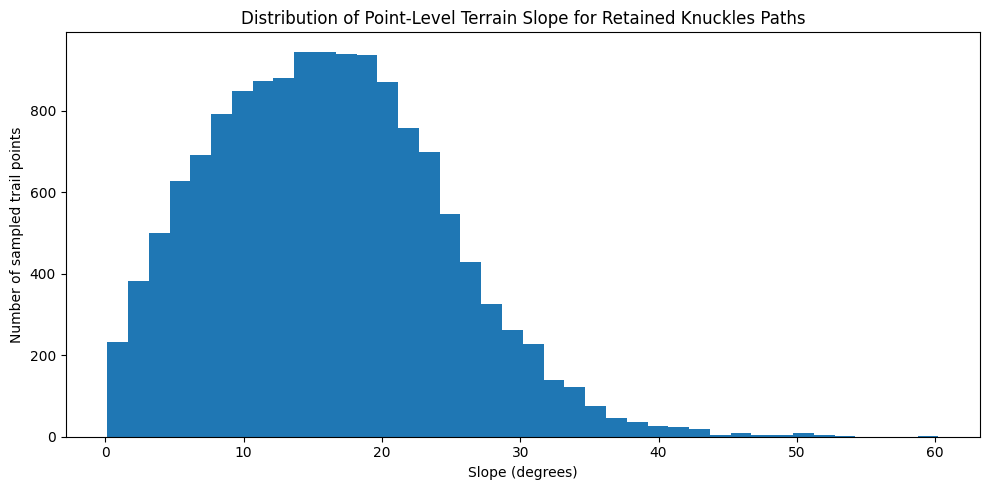

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(
    retained_elevation_points["slope_deg"].dropna(),
    bins=40
)

plt.xlabel("Slope (degrees)")
plt.ylabel("Number of sampled trail points")
plt.title(
    "Distribution of Point-Level Terrain Slope "
    "for Retained Knuckles Paths"
)

plt.tight_layout()
plt.show()

In [25]:
steepest_points = (
    retained_elevation_points
    .sort_values(
        "slope_deg",
        ascending=False
    )
    .head(20)
)

steepest_points[
    [
        "trail_id",
        "point_index",
        "latitude",
        "longitude",
        "chainage_m",
        "elevation_m",
        "slope_deg"
    ]
]

,trail_id,point_index,latitude,longitude,chainage_m,elevation_m,slope_deg
8809,way/760824810,43,7.399427,80.820083,2297.744011,1340.331543,60.243735
10992,way/935829324,15,7.387963,80.723137,353.658484,1102.364380,53.424294
10991,way/935829324,14,7.387897,80.723169,345.479124,1129.740601,52.300384
12463,way/1053562611,26,7.448080,80.815853,1123.798298,872.569031,52.285378
10990,way/935829324,13,7.387710,80.723377,314.659526,1091.224487,52.037133
10989,way/935829324,12,7.387600,80.723465,299.063263,1112.087524,51.069088
12028,way/992652984,154,7.417625,80.870443,2183.322097,722.843628,51.002537
12030,way/992652984,156,7.417605,80.870605,2201.496141,722.843628,51.002537
12029,way/992652984,155,7.417604,80.870528,2192.973001,722.843628,51.002537
5465,way/477415189,28,7.553143,80.753749,730.579583,897.695984,50.603561


In [26]:
slope_features = (
    retained_elevation_points
    .groupby("trail_id")
    .agg(
        mean_slope_deg=(
            "slope_deg",
            "mean"
        ),
        median_slope_deg=(
            "slope_deg",
            "median"
        ),
        max_slope_deg=(
            "slope_deg",
            "max"
        ),
        slope_std_deg=(
            "slope_deg",
            "std"
        ),
        terrain_sample_count=(
            "slope_deg",
            "count"
        )
    )
    .reset_index()
)

print("Slope feature rows:", len(slope_features))

slope_features.head()

Slope feature rows: 557


,trail_id,mean_slope_deg,median_slope_deg,max_slope_deg,slope_std_deg,terrain_sample_count
0,way/100146710,13.918208,15.098890,23.867039,5.758717,61
1,way/100146711,14.832362,14.069171,40.775358,6.844455,226
2,way/100148512,16.514309,17.112799,29.440396,6.508441,43
3,way/100398799,10.591099,9.961239,19.830131,7.773502,4
4,way/100398800,18.995272,19.389006,21.946950,2.581091,9


In [27]:
trail_features = trail_features.merge(
    slope_features,
    how="left",
    left_on="id",
    right_on="trail_id",
    validate="one_to_one",
    suffixes=("", "_slope")
)

slope_columns = [
    "mean_slope_deg",
    "median_slope_deg",
    "max_slope_deg",
    "slope_std_deg",
    "terrain_sample_count"
]

print("TERRAIN FEATURE MERGE")
print("=" * 60)

print("Rows:", len(trail_features))

print("\nMissing terrain features:")
print(
    trail_features[slope_columns]
    .isna()
    .sum()
)

print("\nTerrain feature statistics:")
print(
    trail_features[slope_columns]
    .describe()
)

TERRAIN FEATURE MERGE
Rows: 557

Missing terrain features:
mean_slope_deg          0
median_slope_deg        0
max_slope_deg           0
slope_std_deg           0
terrain_sample_count    0
dtype: int64

Terrain feature statistics:
       mean_slope_deg  median_slope_deg  max_slope_deg  slope_std_deg  \
count      557.000000        557.000000     557.000000   5.570000e+02   
mean        14.142678         14.064960      21.267620   4.264270e+00   
std          6.131095          6.395855       9.749720   2.538107e+00   
min          1.555594          1.432881       2.659245   9.424616e-09   
25%          9.529135          9.216250      13.812297   2.396879e+00   
50%         13.876919         13.780578      20.636865   4.039840e+00   
75%         18.580814         18.817427      26.975223   5.822491e+00   
max         33.481021         33.338263      60.243735   1.578135e+01   

       terrain_sample_count  
count            557.000000  
mean              25.556553  
std               42.

## 2. Geographic Context Feature Engineering

Emergency/support facilities and communication infrastructure are spatial
point datasets. To associate these contextual resources with each retained
candidate path, a representative geographic point is derived for every path.

Distance calculations are not performed directly in geographic coordinates
(EPSG:4326), because longitude and latitude are angular measurements.

The trail geometries are first projected to an appropriate metric coordinate
reference system. Representative trail midpoint locations can then be
calculated and used for proximity feature engineering.

These locations are derived from the observed trail geometries and do not
introduce synthetic observations.

In [28]:
print("TRAIL GEOGRAPHIC BOUNDS")
print("=" * 60)

minx, miny, maxx, maxy = trail_features.total_bounds

print(f"Minimum longitude : {minx:.6f}")
print(f"Minimum latitude  : {miny:.6f}")
print(f"Maximum longitude : {maxx:.6f}")
print(f"Maximum latitude  : {maxy:.6f}")

print("\nCurrent CRS:")
print(trail_features.crs)

TRAIL GEOGRAPHIC BOUNDS
Minimum longitude : 80.645192
Minimum latitude  : 7.215807
Maximum longitude : 80.954533
Maximum latitude  : 7.611815

Current CRS:
EPSG:4326


In [29]:
estimated_utm_crs = trail_features.estimate_utm_crs()

print("Estimated UTM CRS:")
print(estimated_utm_crs)

Estimated UTM CRS:
EPSG:32644


In [30]:
trail_features_projected = (
    trail_features
    .to_crs(estimated_utm_crs)
    .copy()
)

print("Projected trail dataset created.")
print("Rows:", len(trail_features_projected))
print("CRS:", trail_features_projected.crs)

print("\nGeometry types:")
print(
    trail_features_projected
    .geometry
    .geom_type
    .value_counts()
)

Projected trail dataset created.
Rows: 557
CRS: EPSG:32644

Geometry types:
LineString    557
Name: count, dtype: int64


In [31]:
trail_features_projected[
    "representative_point"
] = trail_features_projected.geometry.interpolate(
    0.5,
    normalized=True
)

print("Representative points created.")

print(
    trail_features_projected[
        "representative_point"
    ].head()
)

Representative points created.
0    POINT (468225.341 820299.314)
1    POINT (467273.848 819981.878)
2     POINT (468199.43 821292.823)
3    POINT (464759.995 815794.394)
4    POINT (464553.042 816175.401)
Name: representative_point, dtype: geometry


In [32]:
representative_points = gpd.GeoDataFrame(
    trail_features_projected[
        ["id"]
    ].copy(),
    geometry=trail_features_projected[
        "representative_point"
    ],
    crs=estimated_utm_crs
)

representative_points = (
    representative_points
    .to_crs("EPSG:4326")
)

representative_points[
    "representative_longitude"
] = representative_points.geometry.x

representative_points[
    "representative_latitude"
] = representative_points.geometry.y

representative_points.head()

,id,geometry,representative_longitude,representative_latitude
0,way/100146710,POINT (80.71205 7.421),80.712054,7.420997
1,way/100146711,POINT (80.70343 7.41812),80.703434,7.418119
2,way/100148512,POINT (80.71181 7.42998),80.711814,7.429983
3,way/100398799,POINT (80.68068 7.38023),80.680681,7.380225
4,way/100398800,POINT (80.6788 7.38367),80.678803,7.383670


In [33]:
coordinate_features = representative_points[
    [
        "id",
        "representative_latitude",
        "representative_longitude"
    ]
].copy()

trail_features = trail_features.merge(
    coordinate_features,
    on="id",
    how="left",
    validate="one_to_one"
)

print("REPRESENTATIVE LOCATION FEATURES")
print("=" * 60)

print("Rows:", len(trail_features))

print("\nMissing representative coordinates:")
print(
    trail_features[
        [
            "representative_latitude",
            "representative_longitude"
        ]
    ].isna().sum()
)

print("\nCoordinate statistics:")
print(
    trail_features[
        [
            "representative_latitude",
            "representative_longitude"
        ]
    ].describe()
)

REPRESENTATIVE LOCATION FEATURES
Rows: 557

Missing representative coordinates:
representative_latitude     0
representative_longitude    0
dtype: int64

Coordinate statistics:
       representative_latitude  representative_longitude
count               557.000000                557.000000
mean                  7.376465                 80.746153
std                   0.082938                  0.071368
min                   7.235692                 80.649045
25%                   7.298968                 80.689459
50%                   7.377999                 80.727076
75%                   7.412564                 80.787669
max                   7.604731                 80.951739


## 3. Emergency and Support Facility Proximity Features

Emergency and support facility locations are integrated with the retained
candidate paths to represent accessibility and remoteness context.

The available OpenStreetMap dataset contains hospitals, police stations,
clinics, doctors, shelters, drinking-water locations, and a ranger station.

For each trail, straight-line geographic proximity to the nearest mapped
facility of each relevant category is calculated from the trail geometry.

Distances are calculated in the projected UTM coordinate reference system
(EPSG:32644) and converted from metres to kilometres.

These variables represent geographic proximity to mapped facilities.
They do not represent travel time, road-network distance, facility quality,
opening status, or guaranteed emergency response time.

In [34]:
emergency_file = (
    RAW_DIR
    / "emergency"
    / "knuckles_facilities.geojson"
)

if not emergency_file.exists():
    raise FileNotFoundError(
        f"Emergency facility file not found: {emergency_file}"
    )

emergency = gpd.read_file(emergency_file)

print("EMERGENCY FACILITIES")
print("=" * 60)

print("Rows:", len(emergency))
print("CRS:", emergency.crs)

print("\nFacility categories:")
print(
    emergency["amenity"]
    .value_counts(dropna=False)
)

print("\nGeometry types:")
print(
    emergency.geometry
    .geom_type
    .value_counts()
)

EMERGENCY FACILITIES
Rows: 51
CRS: EPSG:4326

Facility categories:
amenity
hospital          24
police            12
shelter            4
doctors            4
clinic             3
drinking_water     2
None               1
ranger_station     1
Name: count, dtype: int64

Geometry types:
Point         44
LineString     7
Name: count, dtype: int64


In [35]:
missing_amenity = emergency[
    emergency["amenity"].isna()
].copy()

print(
    "Records without amenity:",
    len(missing_amenity)
)

if len(missing_amenity) > 0:
    display(
        missing_amenity[
            [
                col for col in [
                    "id",
                    "name",
                    "amenity",
                    "emergency",
                    "healthcare",
                    "tourism",
                    "shelter_type",
                    "tags",
                    "geometry"
                ]
                if col in missing_amenity.columns
            ]
        ]
    )

Records without amenity: 1


,id,name,amenity,emergency,healthcare,tourism,shelter_type,tags,geometry
43,node/14112228102,Natural Water Spring,None,None,None,None,None,"{ ""drinking_water"": ""yes"", ""intermittent"": ""no"", ""name"": ""Natural Water Spring"", ""natural"": ""spring"" }",POINT (80.76143 7.39206)


In [36]:
emergency_projected = (
    emergency
    .to_crs(estimated_utm_crs)
    .copy()
)

print("Projected emergency facilities:")
print("Rows:", len(emergency_projected))
print("CRS:", emergency_projected.crs)

print("\nMissing geometry:")
print(
    emergency_projected.geometry.isna().sum()
)

print("\nEmpty geometry:")
print(
    emergency_projected.geometry.is_empty.sum()
)

print("\nInvalid geometry:")
print(
    (~emergency_projected.geometry.is_valid).sum()
)

Projected emergency facilities:
Rows: 51
CRS: EPSG:32644

Missing geometry:
0

Empty geometry:
0

Invalid geometry:
0


In [37]:
facility_categories = [
    "hospital",
    "police",
    "clinic",
    "doctors",
    "shelter",
    "drinking_water",
    "ranger_station"
]

facility_counts = (
    emergency_projected["amenity"]
    .value_counts()
    .reindex(
        facility_categories,
        fill_value=0
    )
)

print("FACILITIES USED FOR PROXIMITY FEATURES")
print("=" * 60)

print(facility_counts)

print(
    "\nTotal categorized facilities:",
    facility_counts.sum()
)

FACILITIES USED FOR PROXIMITY FEATURES
amenity
hospital          24
police            12
clinic             3
doctors            4
shelter            4
drinking_water     2
ranger_station     1
Name: count, dtype: int64

Total categorized facilities: 50


In [38]:
def nearest_distance_km(
    trail_geometry,
    facility_geometries
):
    """
    Calculate minimum straight-line distance from a trail geometry
    to the nearest mapped facility geometry.

    Input geometries must use the same projected CRS.
    """

    if len(facility_geometries) == 0:
        return np.nan

    distances_m = facility_geometries.distance(
        trail_geometry
    )

    return distances_m.min() / 1000.0

In [39]:
emergency_distance_columns = []

for category in facility_categories:

    category_facilities = emergency_projected[
        emergency_projected["amenity"] == category
    ]

    column_name = (
        f"nearest_{category}_km"
    )

    trail_features_projected[
        column_name
    ] = trail_features_projected.geometry.apply(
        lambda geom: nearest_distance_km(
            geom,
            category_facilities.geometry
        )
    )

    emergency_distance_columns.append(
        column_name
    )

print("Created emergency proximity features:")

for column in emergency_distance_columns:
    print("-", column)

Created emergency proximity features:
- nearest_hospital_km
- nearest_police_km
- nearest_clinic_km
- nearest_doctors_km
- nearest_shelter_km
- nearest_drinking_water_km
- nearest_ranger_station_km


In [40]:
print("EMERGENCY PROXIMITY VALIDATION")
print("=" * 60)

print("\nMissing values:")
print(
    trail_features_projected[
        emergency_distance_columns
    ].isna().sum()
)

print("\nNegative distances:")
print(
    (
        trail_features_projected[
            emergency_distance_columns
        ] < 0
    ).sum()
)

print("\nDistance statistics (km):")
display(
    trail_features_projected[
        emergency_distance_columns
    ].describe().T
)

EMERGENCY PROXIMITY VALIDATION

Missing values:
nearest_hospital_km          0
nearest_police_km            0
nearest_clinic_km            0
nearest_doctors_km           0
nearest_shelter_km           0
nearest_drinking_water_km    0
nearest_ranger_station_km    0
dtype: int64

Negative distances:
nearest_hospital_km          0
nearest_police_km            0
nearest_clinic_km            0
nearest_doctors_km           0
nearest_shelter_km           0
nearest_drinking_water_km    0
nearest_ranger_station_km    0
dtype: int64

Distance statistics (km):


,count,mean,std,min,25%,50%,75%,max
nearest_hospital_km,557.0,3.063326,2.462704,0.060489,1.325606,2.226207,4.382025,10.871615
nearest_police_km,557.0,4.950187,2.777760,0.244558,2.522948,4.538792,7.373892,13.715821
nearest_clinic_km,557.0,10.225300,5.905435,0.102468,5.450553,10.096498,13.671379,27.023296
nearest_doctors_km,557.0,10.322222,5.201775,0.200630,7.152373,9.581382,12.425055,26.754598
nearest_shelter_km,557.0,8.932254,5.447033,0.016000,4.690555,7.759090,11.841401,25.191281
nearest_drinking_water_km,557.0,9.172096,5.134812,0.019309,6.189603,8.166892,11.511234,29.518754
nearest_ranger_station_km,557.0,16.701396,7.064880,0.004376,11.720833,16.647948,22.026100,34.069927


In [41]:
emergency_features = (
    trail_features_projected[
        ["id"] + emergency_distance_columns
    ]
    .copy()
)

trail_features = trail_features.merge(
    emergency_features,
    on="id",
    how="left",
    validate="one_to_one"
)

print("FINAL EMERGENCY FEATURE MERGE")
print("=" * 60)

print("Rows:", len(trail_features))

print("\nMissing values:")
print(
    trail_features[
        emergency_distance_columns
    ].isna().sum()
)

trail_features[
    ["id"] + emergency_distance_columns
].head()

FINAL EMERGENCY FEATURE MERGE
Rows: 557

Missing values:
nearest_hospital_km          0
nearest_police_km            0
nearest_clinic_km            0
nearest_doctors_km           0
nearest_shelter_km           0
nearest_drinking_water_km    0
nearest_ranger_station_km    0
dtype: int64


,id,nearest_hospital_km,nearest_police_km,nearest_clinic_km,nearest_doctors_km,nearest_shelter_km,nearest_drinking_water_km,nearest_ranger_station_km
0,way/100146710,3.053855,4.297341,15.273782,12.776194,13.882600,3.779496,18.948474
1,way/100146711,2.608764,3.256860,14.794143,12.250359,13.367371,3.237345,18.573782
2,way/100148512,3.915392,3.958396,16.430031,13.931037,15.076627,3.191556,19.768636
3,way/100398799,4.639247,7.373892,10.948848,11.673902,10.749667,8.701008,20.657666
4,way/100398800,5.039593,7.791831,11.339024,12.036890,11.164583,8.350660,20.906266


In [42]:
drinking_water_mask = (
    emergency_projected["amenity"].eq("drinking_water")
)

if "drinking_water" in emergency_projected.columns:
    drinking_water_mask |= (
        emergency_projected["drinking_water"]
        .fillna("")
        .astype(str)
        .str.lower()
        .eq("yes")
    )

drinking_water_facilities = emergency_projected[
    drinking_water_mask
].copy()

print("DRINKING-WATER FACILITIES")
print("=" * 60)

print(
    "Total usable drinking-water locations:",
    len(drinking_water_facilities)
)

display(
    drinking_water_facilities[
        [
            col for col in [
                "id",
                "name",
                "amenity",
                "drinking_water",
                "natural",
                "geometry"
            ]
            if col in drinking_water_facilities.columns
        ]
    ]
)

DRINKING-WATER FACILITIES
Total usable drinking-water locations: 3


,id,name,amenity,drinking_water,natural,geometry
27,node/6050393886,None,drinking_water,None,None,POINT (478020.071 808945.676)
40,node/9773965641,Water Tap,drinking_water,None,None,POINT (466362.575 824363.912)
43,node/14112228102,Natural Water Spring,None,yes,spring,POINT (473672.054 817097.258)


In [43]:
trail_features_projected[
    "nearest_drinking_water_km"
] = trail_features_projected.geometry.apply(
    lambda geom: nearest_distance_km(
        geom,
        drinking_water_facilities.geometry
    )
)

print("UPDATED DRINKING-WATER PROXIMITY")
print("=" * 60)

print(
    trail_features_projected[
        "nearest_drinking_water_km"
    ].describe()
)

print(
    "\nMissing values:",
    trail_features_projected[
        "nearest_drinking_water_km"
    ].isna().sum()
)

UPDATED DRINKING-WATER PROXIMITY
count    557.000000
mean       7.843824
std        5.360112
min        0.001456
25%        3.869216
50%        6.272141
75%       10.480470
max       27.482993
Name: nearest_drinking_water_km, dtype: float64

Missing values: 0


In [44]:
updated_water_distance = (
    trail_features_projected
    .set_index("id")[
        "nearest_drinking_water_km"
    ]
)

trail_features[
    "nearest_drinking_water_km"
] = trail_features["id"].map(
    updated_water_distance
)

print("UPDATED FEATURE VALIDATION")
print("=" * 60)

print("Rows:", len(trail_features))

print(
    "Missing drinking-water distances:",
    trail_features[
        "nearest_drinking_water_km"
    ].isna().sum()
)

print("\nUpdated distance statistics:")

print(
    trail_features[
        "nearest_drinking_water_km"
    ].describe()
)

UPDATED FEATURE VALIDATION
Rows: 557
Missing drinking-water distances: 0

Updated distance statistics:
count    557.000000
mean       7.843824
std        5.360112
min        0.001456
25%        3.869216
50%        6.272141
75%       10.480470
max       27.482993
Name: nearest_drinking_water_km, dtype: float64


## 4. Communication Infrastructure Proxy Features

The available connectivity-related dataset contains 12 OpenStreetMap-mapped
communication structures within the Knuckles study region.

The structures are mapped as communication towers or masts. At least one
record explicitly identifies GSM 900 technology. However, direct cellular
coverage is not known for these records, and dedicated mobile-phone tags are
absent.

Therefore, these locations are not treated as verified mobile network
coverage observations.

Instead, geographic proximity to mapped communication infrastructure is used
as a transparent contextual proxy for communication infrastructure remoteness.

For each retained trail, the minimum straight-line distance from the actual
trail geometry to the nearest mapped communication structure is calculated
in the projected UTM coordinate reference system.

The resulting feature:

`nearest_communication_structure_km`

must not be interpreted as mobile signal strength, network availability,
or guaranteed cellular coverage.

In [45]:
connectivity_file = (
    RAW_DIR
    / "connectivity"
    / "knuckles_osm_communication_structures.geojson"
)

if not connectivity_file.exists():
    raise FileNotFoundError(
        f"Connectivity dataset not found: {connectivity_file}"
    )

connectivity = gpd.read_file(
    connectivity_file
)

print("COMMUNICATION INFRASTRUCTURE")
print("=" * 60)

print("Rows:", len(connectivity))
print("CRS:", connectivity.crs)

print("\nGeometry types:")
print(
    connectivity.geometry
    .geom_type
    .value_counts()
)

print("\nCoverage known:")
print(
    connectivity["coverage_known"]
    .value_counts(dropna=False)
)

print("\nMobile phone tag present:")
print(
    connectivity[
        "osm_mobile_phone_tag_present"
    ].value_counts(dropna=False)
)

COMMUNICATION INFRASTRUCTURE
Rows: 12
CRS: EPSG:4326

Geometry types:
Point    12
Name: count, dtype: int64

Coverage known:
coverage_known
False    12
Name: count, dtype: int64

Mobile phone tag present:
osm_mobile_phone_tag_present
False    12
Name: count, dtype: int64


In [46]:
connectivity_projected = (
    connectivity
    .to_crs(estimated_utm_crs)
    .copy()
)

print("CONNECTIVITY GEOMETRY VALIDATION")
print("=" * 60)

print("Rows:", len(connectivity_projected))
print("CRS:", connectivity_projected.crs)

print(
    "Missing geometries:",
    connectivity_projected.geometry.isna().sum()
)

print(
    "Empty geometries:",
    connectivity_projected.geometry.is_empty.sum()
)

print(
    "Invalid geometries:",
    (~connectivity_projected.geometry.is_valid).sum()
)

CONNECTIVITY GEOMETRY VALIDATION
Rows: 12
CRS: EPSG:32644
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0


In [47]:
trail_features_projected[
    "nearest_communication_structure_km"
] = trail_features_projected.geometry.apply(
    lambda geom: nearest_distance_km(
        geom,
        connectivity_projected.geometry
    )
)

print(
    "Communication proximity feature created."
)

Communication proximity feature created.


In [48]:
communication_column = (
    "nearest_communication_structure_km"
)

print("COMMUNICATION PROXY VALIDATION")
print("=" * 60)

print(
    "Missing values:",
    trail_features_projected[
        communication_column
    ].isna().sum()
)

print(
    "Negative values:",
    (
        trail_features_projected[
            communication_column
        ] < 0
    ).sum()
)

print("\nDistance statistics (km):")

print(
    trail_features_projected[
        communication_column
    ].describe()
)

COMMUNICATION PROXY VALIDATION
Missing values: 0
Negative values: 0

Distance statistics (km):
count    557.000000
mean       5.089866
std        4.102458
min        0.024421
25%        2.260805
50%        4.241079
75%        7.081592
max       23.698375
Name: nearest_communication_structure_km, dtype: float64


In [49]:
communication_features = (
    trail_features_projected[
        [
            "id",
            "nearest_communication_structure_km"
        ]
    ]
    .copy()
)

trail_features = trail_features.merge(
    communication_features,
    on="id",
    how="left",
    validate="one_to_one"
)

print("COMMUNICATION FEATURE MERGE")
print("=" * 60)

print("Rows:", len(trail_features))

print(
    "Missing communication distances:",
    trail_features[
        "nearest_communication_structure_km"
    ].isna().sum()
)

trail_features[
    [
        "id",
        "nearest_communication_structure_km"
    ]
].head()

COMMUNICATION FEATURE MERGE
Rows: 557
Missing communication distances: 0


,id,nearest_communication_structure_km
0,way/100146710,2.856976
1,way/100146711,2.408788
2,way/100148512,3.902371
3,way/100398799,1.386504
4,way/100398800,1.316573


In [50]:
most_remote = (
    trail_features[
        [
            "id",
            "name",
            "highway",
            "length_km",
            "representative_latitude",
            "representative_longitude",
            "nearest_communication_structure_km"
        ]
    ]
    .sort_values(
        "nearest_communication_structure_km",
        ascending=False
    )
    .head(15)
)

most_remote

,id,name,highway,length_km,representative_latitude,representative_longitude,nearest_communication_structure_km
462,way/1027452966,None,track,0.641158,7.534691,80.951739,23.698375
175,way/510876230,None,track,0.938224,7.548861,80.950263,23.511152
461,way/1027452965,None,track,0.200814,7.531210,80.945094,23.143501
460,way/1027452964,None,track,2.349279,7.534588,80.947353,22.542733
165,way/504472523,None,path,0.395373,7.584039,80.918533,21.240253
166,way/504472524,None,path,0.310521,7.588399,80.915121,20.930704
167,way/504472527,None,track,0.874830,7.587137,80.909357,20.229720
168,way/504472528,None,path,0.316706,7.582966,80.907715,20.072407
70,way/355074051,None,track,0.761880,7.556333,80.915333,20.064414
71,way/355074066,None,track,0.629517,7.551093,80.914935,19.788207


### Connectivity Proxy Interpretation

The communication-infrastructure proximity feature is retained as contextual
geographic information only.

A larger `nearest_communication_structure_km` value indicates that a trail is
farther from the nearest communication structure represented in the available
OpenStreetMap dataset.

It does not establish that:

- cellular service is unavailable;
- signal strength is weak;
- a particular mobile operator has no coverage;
- the nearest tower provides mobile service;
- proximity guarantees connectivity.

Consequently, this variable will be described as a communication-infrastructure
or remoteness proxy throughout the research rather than as measured network
coverage.

## 5. Trail-Level ML Feature Dataset Construction

The preprocessing stages above produced trail, terrain, emergency-access,
geographic, and communication-infrastructure contextual variables.

This section constructs a clean trail-level feature dataset for subsequent
context-aware offline resource recommendation modelling.

Only observed or deterministically derived features are retained. Sparse OSM
attributes are not artificially filled, and no synthetic observations are
introduced.

The dataset contains one row per retained candidate path.

Important distinctions:

- Geographic coordinates represent the derived midpoint of each path.
- Emergency proximity represents minimum straight-line distance from the
  mapped trail geometry to mapped support facilities.
- Communication proximity is a remoteness proxy and not measured cellular
  coverage.
- `sample_spacing_max_m` and `direction` are preprocessing metadata rather
  than predictive features and are excluded from the ML feature table.

In [51]:
print("CURRENT TRAIL FEATURE TABLE")
print("=" * 60)

print("Rows:", len(trail_features))
print("Columns:", len(trail_features.columns))

for i, column in enumerate(
    trail_features.columns,
    start=1
):
    print(f"{i:02d}. {column}")

CURRENT TRAIL FEATURE TABLE
Rows: 557
Columns: 68
01. id
02. osm_type
03. osm_id
04. tags
05. access
06. bicycle
07. bridge
08. crossing
09. crossing:markings
10. cutting
11. description
12. embankment
13. foot
14. footway
15. highway
16. horse
17. incline
18. informal
19. lanes
20. layer
21. lit
22. maxspeed
23. motor_vehicle
24. motorcycle
25. mtb:scale
26. mtb:scale:uphill
27. name
28. note
29. sac_scale
30. smoothness
31. surface
32. tracktype
33. wheelchair
34. width
35. verified_hiking_trail
36. length_km
37. hiking_relation_ids
38. geometry
39. pedestrian_prohibited
40. pedestrian_permit_required
41. general_access_restricted
42. explicit_non_hiking_note
43. exclude_from_hiking_candidates
44. trail_id
45. minimum_elevation_m
46. maximum_elevation_m
47. elevation_gain_m
48. elevation_loss_m
49. profile_complete
50. sample_spacing_max_m
51. direction
52. elevation_range_m
53. trail_id_slope
54. mean_slope_deg
55. median_slope_deg
56. max_slope_deg
57. slope_std_deg
58. terrain_sam

In [52]:
ml_feature_columns = [
    # Identifier
    "id",

    # Basic trail characteristics
    "highway",
    "length_km",

    # Geographic context
    "representative_latitude",
    "representative_longitude",

    # Elevation
    "minimum_elevation_m",
    "maximum_elevation_m",
    "elevation_range_m",
    "elevation_gain_m",
    "elevation_loss_m",

    # Terrain
    "mean_slope_deg",
    "median_slope_deg",
    "max_slope_deg",
    "slope_std_deg",
    "terrain_sample_count",

    # Emergency/support proximity
    "nearest_hospital_km",
    "nearest_police_km",
    "nearest_clinic_km",
    "nearest_doctors_km",
    "nearest_shelter_km",
    "nearest_drinking_water_km",
    "nearest_ranger_station_km",

    # Communication-infrastructure proxy
    "nearest_communication_structure_km"
]

missing_columns = [
    column
    for column in ml_feature_columns
    if column not in trail_features.columns
]

print("Requested columns:", len(ml_feature_columns))
print("Missing columns:", missing_columns)

Requested columns: 23
Missing columns: []


In [53]:
ml_trail_features = (
    trail_features[
        ml_feature_columns
    ]
    .copy()
)

print("ML TRAIL FEATURE DATASET")
print("=" * 60)

print("Rows:", len(ml_trail_features))
print("Columns:", len(ml_trail_features.columns))

print(
    "\nDuplicate IDs:",
    ml_trail_features["id"].duplicated().sum()
)

print(
    "Missing IDs:",
    ml_trail_features["id"].isna().sum()
)

display(
    ml_trail_features.head()
)

ML TRAIL FEATURE DATASET
Rows: 557
Columns: 23

Duplicate IDs: 0
Missing IDs: 0


,id,highway,length_km,representative_latitude,representative_longitude,minimum_elevation_m,maximum_elevation_m,elevation_range_m,elevation_gain_m,elevation_loss_m,...,slope_std_deg,terrain_sample_count,nearest_hospital_km,nearest_police_km,nearest_clinic_km,nearest_doctors_km,nearest_shelter_km,nearest_drinking_water_km,nearest_ranger_station_km,nearest_communication_structure_km
0,way/100146710,footway,1.654853,7.420997,80.712054,1275.355835,1329.643188,54.287354,137.471680,83.390137,...,5.758717,61,3.053855,4.297341,15.273782,12.776194,13.882600,3.779496,18.948474,2.856976
1,way/100146711,track,4.966901,7.418119,80.703434,1024.330322,1281.052856,256.722534,485.684814,287.749878,...,6.844455,226,2.608764,3.256860,14.794143,12.250359,13.367371,3.237345,18.573782,2.408788
2,way/100148512,track,0.995269,7.429983,80.711814,1332.734375,1420.415405,87.681030,116.777222,29.096191,...,6.508441,43,3.915392,3.958396,16.430031,13.931037,15.076627,3.191556,19.768636,3.902371
3,way/100398799,footway,0.073670,7.380225,80.680681,784.558533,789.260803,4.702271,3.243958,4.702271,...,7.773502,4,4.639247,7.373892,10.948848,11.673902,10.749667,8.701008,20.657666,1.386504
4,way/100398800,steps,0.195638,7.383670,80.678803,696.232178,753.476257,57.244080,57.244080,0.000000,...,2.581091,9,5.039593,7.791831,11.339024,12.036890,11.164583,8.350660,20.906266,1.316573


In [54]:
missing_summary = pd.DataFrame({
    "missing_count":
        ml_trail_features.isna().sum(),
    "missing_percent":
        ml_trail_features.isna().mean() * 100
})

missing_summary = (
    missing_summary[
        missing_summary["missing_count"] > 0
    ]
    .sort_values(
        "missing_count",
        ascending=False
    )
)

print("MISSING VALUE AUDIT")
print("=" * 60)

if len(missing_summary) == 0:
    print("No missing values detected.")
else:
    display(missing_summary)

MISSING VALUE AUDIT
No missing values detected.


In [55]:
numeric_columns = (
    ml_trail_features
    .select_dtypes(include=[np.number])
    .columns
)

print("NUMERICAL FEATURE VALIDATION")
print("=" * 60)

print(
    "Infinite values:",
    np.isinf(
        ml_trail_features[
            numeric_columns
        ]
    ).sum().sum()
)

print(
    "Negative length:",
    (
        ml_trail_features["length_km"] < 0
    ).sum()
)

print(
    "Negative elevation range:",
    (
        ml_trail_features[
            "elevation_range_m"
        ] < 0
    ).sum()
)

print(
    "Negative elevation gain:",
    (
        ml_trail_features[
            "elevation_gain_m"
        ] < 0
    ).sum()
)

print(
    "Negative emergency distances:",
    (
        ml_trail_features[
            emergency_distance_columns
        ] < 0
    ).sum().sum()
)

print(
    "Negative communication distances:",
    (
        ml_trail_features[
            "nearest_communication_structure_km"
        ] < 0
    ).sum()
)

NUMERICAL FEATURE VALIDATION
Infinite values: 0
Negative length: 0
Negative elevation range: 0
Negative elevation gain: 0
Negative emergency distances: 0
Negative communication distances: 0


In [56]:
ml_dataset_dir = (
    PROCESSED_DIR
    / "features"
)

ml_dataset_dir.mkdir(
    parents=True,
    exist_ok=True
)

ml_dataset_file = (
    ml_dataset_dir
    / "knuckles_trail_context_features.csv"
)

ml_trail_features.to_csv(
    ml_dataset_file,
    index=False
)

print("Dataset saved successfully.")
print("Path:", ml_dataset_file)
print("Rows:", len(ml_trail_features))
print("Columns:", len(ml_trail_features.columns))

Dataset saved successfully.
Path: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed/features/knuckles_trail_context_features.csv
Rows: 557
Columns: 23


In [57]:
saved_ml_features = pd.read_csv(
    ml_dataset_file
)

print("SAVED DATASET VERIFICATION")
print("=" * 60)

print(
    "Shape:",
    saved_ml_features.shape
)

print(
    "Duplicate IDs:",
    saved_ml_features["id"]
    .duplicated()
    .sum()
)

print(
    "Total missing values:",
    saved_ml_features
    .isna()
    .sum()
    .sum()
)

display(
    saved_ml_features.head()
)

SAVED DATASET VERIFICATION
Shape: (557, 23)
Duplicate IDs: 0
Total missing values: 0


,id,highway,length_km,representative_latitude,representative_longitude,minimum_elevation_m,maximum_elevation_m,elevation_range_m,elevation_gain_m,elevation_loss_m,...,slope_std_deg,terrain_sample_count,nearest_hospital_km,nearest_police_km,nearest_clinic_km,nearest_doctors_km,nearest_shelter_km,nearest_drinking_water_km,nearest_ranger_station_km,nearest_communication_structure_km
0,way/100146710,footway,1.654853,7.420997,80.712054,1275.355835,1329.643188,54.287354,137.471680,83.390137,...,5.758717,61,3.053855,4.297341,15.273782,12.776194,13.882600,3.779496,18.948474,2.856976
1,way/100146711,track,4.966901,7.418119,80.703434,1024.330322,1281.052856,256.722534,485.684814,287.749878,...,6.844455,226,2.608764,3.256860,14.794143,12.250359,13.367371,3.237345,18.573782,2.408788
2,way/100148512,track,0.995269,7.429983,80.711814,1332.734375,1420.415405,87.681030,116.777222,29.096191,...,6.508441,43,3.915392,3.958396,16.430031,13.931037,15.076627,3.191556,19.768636,3.902371
3,way/100398799,footway,0.073670,7.380225,80.680681,784.558533,789.260803,4.702271,3.243958,4.702271,...,7.773502,4,4.639247,7.373892,10.948848,11.673902,10.749667,8.701008,20.657666,1.386504
4,way/100398800,steps,0.195638,7.383670,80.678803,696.232178,753.476257,57.244080,57.244080,0.000000,...,2.581091,9,5.039593,7.791831,11.339024,12.036890,11.164583,8.350660,20.906266,1.316573


## 6. Historical Weather Context Engineering

Historical hourly weather observations from 2021–2025 are used to characterize
environmental conditions within the Knuckles study region.

The weather dataset contains observations from five geographic locations and
includes temperature, apparent temperature, relative humidity, precipitation,
weather code, cloud cover, wind speed, wind gusts, and surface pressure.

Historical weather is not interpreted as the weather experienced on every
individual trail traversal. Instead, it is used to derive defensible
environmental context and to establish the weather variables required by the
offline-resource recommendation model.

Trail locations are spatially associated with the nearest available weather
reference location.

No synthetic weather observations are generated.

In [58]:
weather_dir = (
    PROCESSED_DIR
    / "weather"
)

weather_files = sorted(
    weather_dir.glob("*.csv")
)

print("WEATHER FILES")
print("=" * 60)

print("Files found:", len(weather_files))

for file in weather_files:
    print("-", file.name)

WEATHER FILES
Files found: 14
- adams_peak_0_hourly.csv
- ella_0_hourly.csv
- haputale_0_hourly.csv
- horton_plains_0_hourly.csv
- knuckles_0_hourly.csv
- knuckles_1_hourly.csv
- knuckles_2_hourly.csv
- knuckles_3_hourly.csv
- knuckles_4_hourly.csv
- meemure_0_hourly.csv
- namunukula_0_hourly.csv
- riverston_0_hourly.csv
- sigiriya_pidurangala_0_hourly.csv
- sinharaja_0_hourly.csv


In [59]:
weather_frames = []

for file in weather_files:
    frame = pd.read_csv(file)

    frame["source_file"] = file.name

    weather_frames.append(frame)

weather = pd.concat(
    weather_frames,
    ignore_index=True
)

print("COMBINED WEATHER DATA")
print("=" * 60)

print("Rows:", len(weather))
print("Columns:", len(weather.columns))

print("\nColumns:")
for column in weather.columns:
    print("-", column)

display(weather.head())

COMBINED WEATHER DATA
Rows: 613536
Columns: 19

Columns:
- point_id
- region
- requested_latitude
- requested_longitude
- grid_latitude
- grid_longitude
- api_elevation_m
- timestamp
- temperature_2m
- apparent_temperature
- relative_humidity_2m
- precipitation
- rain
- weather_code
- cloud_cover
- wind_speed_10m
- wind_gusts_10m
- surface_pressure
- source_file


,point_id,region,requested_latitude,requested_longitude,grid_latitude,grid_longitude,api_elevation_m,timestamp,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,weather_code,cloud_cover,wind_speed_10m,wind_gusts_10m,surface_pressure,source_file
0,adams_peak_0,adams_peak,6.825,80.515,6.800003,80.600006,1294.0,2021-01-01T00:00:00Z,17.7,19.6,92,0.0,0.0,3,99,2.6,11.2,869.8,adams_peak_0_hourly.csv
1,adams_peak_0,adams_peak,6.825,80.515,6.800003,80.600006,1294.0,2021-01-01T01:00:00Z,17.5,19.4,93,0.0,0.0,3,97,2.5,10.1,870.5,adams_peak_0_hourly.csv
2,adams_peak_0,adams_peak,6.825,80.515,6.800003,80.600006,1294.0,2021-01-01T02:00:00Z,18.7,20.9,91,0.0,0.0,3,99,2.7,13.0,871.6,adams_peak_0_hourly.csv
3,adams_peak_0,adams_peak,6.825,80.515,6.800003,80.600006,1294.0,2021-01-01T03:00:00Z,20.1,22.5,83,0.0,0.0,3,100,1.0,12.6,873.2,adams_peak_0_hourly.csv
4,adams_peak_0,adams_peak,6.825,80.515,6.800003,80.600006,1294.0,2021-01-01T04:00:00Z,21.4,24.0,79,0.0,0.0,3,99,1.0,13.3,874.0,adams_peak_0_hourly.csv


In [60]:
print("WEATHER DATA VALIDATION")
print("=" * 60)

print("Shape:", weather.shape)

print(
    "\nTotal missing values:",
    weather.isna().sum().sum()
)

print("\nMissing values by column:")

weather_missing = (
    weather.isna()
    .sum()
    .sort_values(ascending=False)
)

print(
    weather_missing[
        weather_missing > 0
    ]
)

print("\nDuplicate rows:")
print(
    weather.duplicated().sum()
)

WEATHER DATA VALIDATION
Shape: (613536, 19)

Total missing values: 0

Missing values by column:
Series([], dtype: int64)

Duplicate rows:
0


In [61]:
candidate_location_columns = [
    column
    for column in weather.columns
    if any(
        keyword in column.lower()
        for keyword in [
            "latitude",
            "longitude",
            "location",
            "region",
            "site"
        ]
    )
]

candidate_time_columns = [
    column
    for column in weather.columns
    if any(
        keyword in column.lower()
        for keyword in [
            "time",
            "date"
        ]
    )
]

print("POTENTIAL LOCATION COLUMNS")
print("=" * 60)
print(candidate_location_columns)

print("\nPOTENTIAL TIME COLUMNS")
print("=" * 60)
print(candidate_time_columns)

POTENTIAL LOCATION COLUMNS
['region', 'requested_latitude', 'requested_longitude', 'grid_latitude', 'grid_longitude']

POTENTIAL TIME COLUMNS
['timestamp']


In [62]:
knuckles_weather = (
    weather[
        weather["region"].eq("knuckles")
    ]
    .copy()
    .reset_index(drop=True)
)

print("KNUCKLES WEATHER DATA")
print("=" * 60)

print("Rows:", len(knuckles_weather))
print("Columns:", len(knuckles_weather.columns))

print("\nUnique weather points:")
print(
    knuckles_weather["point_id"]
    .value_counts()
    .sort_index()
)

print("\nUnique source files:")
print(
    knuckles_weather["source_file"]
    .value_counts()
    .sort_index()
)

KNUCKLES WEATHER DATA
Rows: 219120
Columns: 19

Unique weather points:
point_id
knuckles_0    43824
knuckles_1    43824
knuckles_2    43824
knuckles_3    43824
knuckles_4    43824
Name: count, dtype: int64

Unique source files:
source_file
knuckles_0_hourly.csv    43824
knuckles_1_hourly.csv    43824
knuckles_2_hourly.csv    43824
knuckles_3_hourly.csv    43824
knuckles_4_hourly.csv    43824
Name: count, dtype: int64


In [63]:
knuckles_weather["timestamp"] = pd.to_datetime(
    knuckles_weather["timestamp"],
    utc=True
)

print("TEMPORAL COVERAGE")
print("=" * 60)

print(
    "Start:",
    knuckles_weather["timestamp"].min()
)

print(
    "End:",
    knuckles_weather["timestamp"].max()
)

print(
    "Unique timestamps:",
    knuckles_weather["timestamp"].nunique()
)

print("\nRecords by year:")

print(
    knuckles_weather["timestamp"]
    .dt.year
    .value_counts()
    .sort_index()
)

TEMPORAL COVERAGE
Start: 2021-01-01 00:00:00+00:00
End: 2025-12-31 23:00:00+00:00
Unique timestamps: 43824

Records by year:
timestamp
2021    43800
2022    43800
2023    43800
2024    43920
2025    43800
Name: count, dtype: int64


In [64]:
weather_locations = (
    knuckles_weather[
        [
            "point_id",
            "requested_latitude",
            "requested_longitude",
            "grid_latitude",
            "grid_longitude",
            "api_elevation_m"
        ]
    ]
    .drop_duplicates()
    .sort_values("point_id")
    .reset_index(drop=True)
)

print("KNUCKLES WEATHER REFERENCE LOCATIONS")
print("=" * 60)

print(
    "Unique locations:",
    len(weather_locations)
)

display(weather_locations)

KNUCKLES WEATHER REFERENCE LOCATIONS
Unique locations: 5


,point_id,requested_latitude,requested_longitude,grid_latitude,grid_longitude,api_elevation_m
0,knuckles_0,7.45,80.8,7.400002,80.800020,1151.0
1,knuckles_1,7.30,80.7,7.300003,80.700010,464.0
2,knuckles_2,7.30,80.9,7.300003,80.899994,790.0
3,knuckles_3,7.55,80.7,7.500000,80.700010,1007.0
4,knuckles_4,7.55,80.9,7.599998,80.899994,142.0


In [65]:
weather_point_validation = (
    knuckles_weather
    .groupby("point_id")
    .agg(
        records=("timestamp", "size"),
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        unique_timestamps=("timestamp", "nunique"),
        requested_latitude=(
            "requested_latitude",
            "nunique"
        ),
        requested_longitude=(
            "requested_longitude",
            "nunique"
        )
    )
)

display(weather_point_validation)

,records,start_time,end_time,unique_timestamps,requested_latitude,requested_longitude
point_id,,,,,,
knuckles_0,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,43824,1,1
knuckles_1,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,43824,1,1
knuckles_2,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,43824,1,1
knuckles_3,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,43824,1,1
knuckles_4,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,43824,1,1


In [66]:
weather_locations_gdf = gpd.GeoDataFrame(
    weather_locations.copy(),
    geometry=gpd.points_from_xy(
        weather_locations[
            "requested_longitude"
        ],
        weather_locations[
            "requested_latitude"
        ]
    ),
    crs="EPSG:4326"
)

weather_locations_projected = (
    weather_locations_gdf
    .to_crs(estimated_utm_crs)
)

print("WEATHER LOCATION GEOMETRIES")
print("=" * 60)

print(
    "Rows:",
    len(weather_locations_projected)
)

print(
    "CRS:",
    weather_locations_projected.crs
)

print(
    "Geometry types:"
)

print(
    weather_locations_projected
    .geometry
    .geom_type
    .value_counts()
)

WEATHER LOCATION GEOMETRIES
Rows: 5
CRS: EPSG:32644
Geometry types:
Point    5
Name: count, dtype: int64


In [67]:
trail_weather_points = gpd.GeoDataFrame(
    trail_features[
        [
            "id",
            "representative_latitude",
            "representative_longitude"
        ]
    ].copy(),
    geometry=gpd.points_from_xy(
        trail_features[
            "representative_longitude"
        ],
        trail_features[
            "representative_latitude"
        ]
    ),
    crs="EPSG:4326"
)

trail_weather_points = (
    trail_weather_points
    .to_crs(estimated_utm_crs)
)

print("Trail weather matching points:")
print(len(trail_weather_points))

print("CRS:")
print(trail_weather_points.crs)

Trail weather matching points:
557
CRS:
EPSG:32644


In [68]:
trail_weather_match = gpd.sjoin_nearest(
    trail_weather_points,
    weather_locations_projected[
        [
            "point_id",
            "api_elevation_m",
            "geometry"
        ]
    ],
    how="left",
    distance_col="weather_station_distance_m"
)

trail_weather_match[
    "weather_station_distance_km"
] = (
    trail_weather_match[
        "weather_station_distance_m"
    ] / 1000.0
)

print("TRAIL → WEATHER MATCHING")
print("=" * 60)

print(
    "Rows:",
    len(trail_weather_match)
)

print(
    "Missing weather point:",
    trail_weather_match[
        "point_id"
    ].isna().sum()
)

print(
    "Duplicate trail IDs:",
    trail_weather_match[
        "id"
    ].duplicated().sum()
)

print("\nAssigned weather points:")

print(
    trail_weather_match[
        "point_id"
    ].value_counts()
)

print("\nMatching distance (km):")

print(
    trail_weather_match[
        "weather_station_distance_km"
    ].describe()
)

TRAIL → WEATHER MATCHING
Rows: 557
Missing weather point: 0
Duplicate trail IDs: 0

Assigned weather points:
point_id
knuckles_1    257
knuckles_0    132
knuckles_3     74
knuckles_2     68
knuckles_4     26
Name: count, dtype: int64

Matching distance (km):
count    557.000000
mean       7.261070
std        2.767046
min        0.640822
25%        5.185860
50%        7.244289
75%        9.702168
max       14.325723
Name: weather_station_distance_km, dtype: float64


In [69]:
farthest_weather_matches = (
    trail_weather_match[
        [
            "id",
            "point_id",
            "representative_latitude",
            "representative_longitude",
            "weather_station_distance_km"
        ]
    ]
    .sort_values(
        "weather_station_distance_km",
        ascending=False
    )
    .head(20)
)

display(
    farthest_weather_matches
)

,id,point_id,representative_latitude,representative_longitude,weather_station_distance_km
515,way/1265415728,knuckles_3,7.429458,80.652347,14.325723
516,way/1265415729,knuckles_3,7.430339,80.652599,14.224910
517,way/1265415730,knuckles_3,7.430343,80.652833,14.215032
159,way/498973170,knuckles_3,7.435979,80.652744,13.640831
514,way/1265415727,knuckles_1,7.413250,80.652282,13.582362
513,way/1265415726,knuckles_1,7.411982,80.651649,13.480761
189,way/565424929,knuckles_1,7.415211,80.671557,13.117700
327,way/816936292,knuckles_0,7.435542,80.692128,12.009950
512,way/1265415725,knuckles_1,7.398630,80.657523,11.868694
511,way/1265415724,knuckles_1,7.398429,80.657868,11.833224


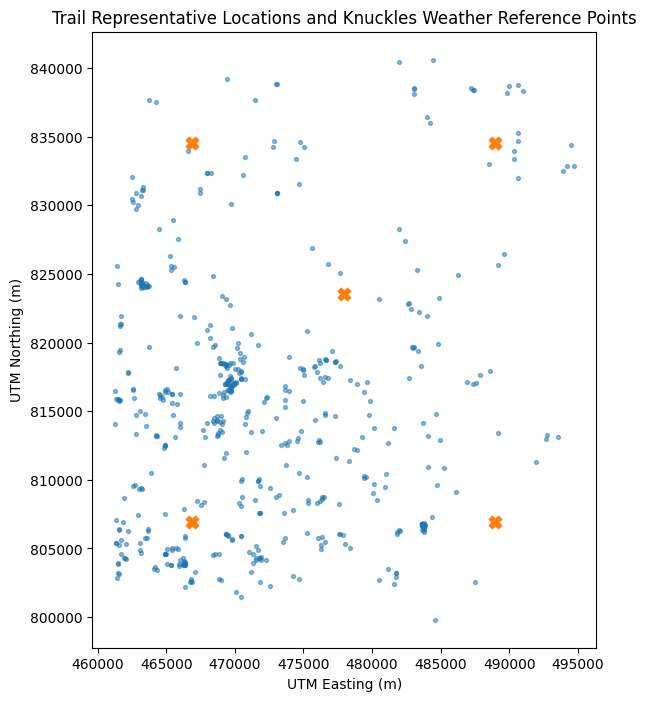

In [70]:
fig, ax = plt.subplots(
    figsize=(8, 8)
)

trail_weather_points.plot(
    ax=ax,
    markersize=8,
    alpha=0.5
)

weather_locations_projected.plot(
    ax=ax,
    markersize=80,
    marker="X"
)

ax.set_title(
    "Trail Representative Locations and "
    "Knuckles Weather Reference Points"
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")

plt.show()

In [71]:
weather_numeric_columns = [
    "temperature_2m",
    "apparent_temperature",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "cloud_cover",
    "wind_speed_10m",
    "wind_gusts_10m",
    "surface_pressure"
]

print("WEATHER VARIABLES")
print("=" * 60)

for column in weather_numeric_columns:
    print(
        f"{column}: "
        f"{knuckles_weather[column].dtype}"
    )

WEATHER VARIABLES
temperature_2m: float64
apparent_temperature: float64
relative_humidity_2m: int64
precipitation: float64
rain: float64
cloud_cover: int64
wind_speed_10m: float64
wind_gusts_10m: float64
surface_pressure: float64


In [72]:
print("HISTORICAL WEATHER RANGES")
print("=" * 60)

display(
    knuckles_weather[
        weather_numeric_columns
    ].describe().T
)

HISTORICAL WEATHER RANGES


,count,mean,std,min,25%,50%,75%,max
temperature_2m,219120.0,23.162950,3.438551,11.9,20.5,22.8,25.4,37.9
apparent_temperature,219120.0,25.918194,4.231824,10.4,22.6,25.4,28.8,43.9
relative_humidity_2m,219120.0,80.513363,13.678115,29.0,72.0,83.0,92.0,100.0
precipitation,219120.0,0.213162,0.849492,0.0,0.0,0.0,0.1,26.3
rain,219120.0,0.213162,0.849492,0.0,0.0,0.0,0.1,26.3
cloud_cover,219120.0,75.166785,30.222895,0.0,54.0,91.0,99.0,100.0
wind_speed_10m,219120.0,7.238126,4.998647,0.0,3.7,5.8,9.3,30.6
wind_gusts_10m,219120.0,23.668858,14.495417,1.1,12.6,20.2,31.0,94.7
surface_pressure,219120.0,932.544547,39.372977,877.8,899.4,922.8,961.0,1003.0


In [73]:
weather_profiles = (
    knuckles_weather
    .groupby("point_id")
    .agg(
        hist_temperature_mean_c=(
            "temperature_2m", "mean"
        ),
        hist_temperature_min_c=(
            "temperature_2m", "min"
        ),
        hist_temperature_max_c=(
            "temperature_2m", "max"
        ),

        hist_apparent_temperature_mean_c=(
            "apparent_temperature", "mean"
        ),
        hist_apparent_temperature_min_c=(
            "apparent_temperature", "min"
        ),
        hist_apparent_temperature_max_c=(
            "apparent_temperature", "max"
        ),

        hist_relative_humidity_mean_pct=(
            "relative_humidity_2m", "mean"
        ),

        hist_precipitation_mean_mm=(
            "precipitation", "mean"
        ),
        hist_precipitation_max_mm=(
            "precipitation", "max"
        ),

        hist_wind_speed_mean_kmh=(
            "wind_speed_10m", "mean"
        ),
        hist_wind_speed_max_kmh=(
            "wind_speed_10m", "max"
        ),

        hist_wind_gust_mean_kmh=(
            "wind_gusts_10m", "mean"
        ),
        hist_wind_gust_max_kmh=(
            "wind_gusts_10m", "max"
        ),

        hist_cloud_cover_mean_pct=(
            "cloud_cover", "mean"
        ),

        hist_surface_pressure_mean_hpa=(
            "surface_pressure", "mean"
        )
    )
    .reset_index()
)

print("HISTORICAL WEATHER PROFILES")
print("=" * 60)

print("Rows:", len(weather_profiles))
print("Columns:", len(weather_profiles.columns))

display(weather_profiles)

HISTORICAL WEATHER PROFILES
Rows: 5
Columns: 16


,point_id,hist_temperature_mean_c,hist_temperature_min_c,hist_temperature_max_c,hist_apparent_temperature_mean_c,hist_apparent_temperature_min_c,hist_apparent_temperature_max_c,hist_relative_humidity_mean_pct,hist_precipitation_mean_mm,hist_precipitation_max_mm,hist_wind_speed_mean_kmh,hist_wind_speed_max_kmh,hist_wind_gust_mean_kmh,hist_wind_gust_max_kmh,hist_cloud_cover_mean_pct,hist_surface_pressure_mean_hpa
0,knuckles_0,20.977788,11.9,31.1,22.480880,10.4,34.6,79.910985,0.212016,26.3,8.644206,30.6,28.444275,94.7,76.436199,885.953975
1,knuckles_1,23.878135,15.0,34.5,27.376846,15.8,40.1,84.656444,0.242785,19.5,7.270071,28.2,26.206131,94.3,76.496098,959.606859
2,knuckles_2,22.392258,13.1,32.8,24.943209,12.3,36.4,79.241169,0.219565,22.2,5.090656,24.0,17.487368,70.2,72.735305,922.830718
3,knuckles_3,21.669072,12.5,31.8,23.598489,11.4,36.2,81.515585,0.212016,26.3,8.644206,30.6,28.444275,94.7,76.436199,900.781471
4,knuckles_4,26.897497,15.2,37.9,31.191546,16.0,43.9,77.242630,0.179427,25.2,6.541491,28.3,17.762240,69.8,73.730125,993.549710


In [74]:
weather_percentiles = (
    knuckles_weather
    .groupby("point_id")
    .agg(
        hist_precipitation_p95_mm=(
            "precipitation",
            lambda x: x.quantile(0.95)
        ),

        hist_wind_speed_p95_kmh=(
            "wind_speed_10m",
            lambda x: x.quantile(0.95)
        ),

        hist_wind_gust_p95_kmh=(
            "wind_gusts_10m",
            lambda x: x.quantile(0.95)
        ),

        hist_temperature_p05_c=(
            "temperature_2m",
            lambda x: x.quantile(0.05)
        ),

        hist_temperature_p95_c=(
            "temperature_2m",
            lambda x: x.quantile(0.95)
        ),

        hist_apparent_temperature_p05_c=(
            "apparent_temperature",
            lambda x: x.quantile(0.05)
        ),

        hist_apparent_temperature_p95_c=(
            "apparent_temperature",
            lambda x: x.quantile(0.95)
        )
    )
    .reset_index()
)

weather_profiles = weather_profiles.merge(
    weather_percentiles,
    on="point_id",
    how="left",
    validate="one_to_one"
)

print("WEATHER PROFILE WITH PERCENTILES")
print("=" * 60)

print("Shape:", weather_profiles.shape)

display(weather_profiles)

WEATHER PROFILE WITH PERCENTILES
Shape: (5, 23)


,point_id,hist_temperature_mean_c,hist_temperature_min_c,hist_temperature_max_c,hist_apparent_temperature_mean_c,hist_apparent_temperature_min_c,hist_apparent_temperature_max_c,hist_relative_humidity_mean_pct,hist_precipitation_mean_mm,hist_precipitation_max_mm,...,hist_wind_gust_max_kmh,hist_cloud_cover_mean_pct,hist_surface_pressure_mean_hpa,hist_precipitation_p95_mm,hist_wind_speed_p95_kmh,hist_wind_gust_p95_kmh,hist_temperature_p05_c,hist_temperature_p95_c,hist_apparent_temperature_p05_c,hist_apparent_temperature_p95_c
0,knuckles_0,20.977788,11.9,31.1,22.480880,10.4,34.6,79.910985,0.212016,26.3,...,94.7,76.436199,885.953975,0.9,20.5,60.10,17.5,25.9,18.9,27.5
1,knuckles_1,23.878135,15.0,34.5,27.376846,15.8,40.1,84.656444,0.242785,19.5,...,94.3,76.496098,959.606859,1.2,17.3,54.40,20.6,28.2,23.5,32.4
2,knuckles_2,22.392258,13.1,32.8,24.943209,12.3,36.4,79.241169,0.219565,22.2,...,70.2,72.735305,922.830718,1.1,12.1,37.74,18.8,27.7,20.8,30.6
3,knuckles_3,21.669072,12.5,31.8,23.598489,11.4,36.2,81.515585,0.212016,26.3,...,94.7,76.436199,900.781471,0.9,20.5,60.10,18.3,26.4,20.0,28.7
4,knuckles_4,26.897497,15.2,37.9,31.191546,16.0,43.9,77.242630,0.179427,25.2,...,69.8,73.730125,993.549710,0.8,17.5,42.80,22.8,32.8,26.9,37.1


In [75]:
rain_frequency = (
    knuckles_weather
    .assign(
        measurable_rain=(
            knuckles_weather["rain"] > 0
        ).astype(int)
    )
    .groupby("point_id")
    .agg(
        hist_rain_hour_fraction=(
            "measurable_rain", "mean"
        )
    )
    .reset_index()
)

weather_profiles = weather_profiles.merge(
    rain_frequency,
    on="point_id",
    how="left",
    validate="one_to_one"
)

weather_profiles[
    "hist_rain_hour_percent"
] = (
    weather_profiles[
        "hist_rain_hour_fraction"
    ] * 100
)

print("RAINFALL FREQUENCY")
print("=" * 60)

display(
    weather_profiles[
        [
            "point_id",
            "hist_rain_hour_fraction",
            "hist_rain_hour_percent"
        ]
    ]
)

RAINFALL FREQUENCY


,point_id,hist_rain_hour_fraction,hist_rain_hour_percent
0,knuckles_0,0.310948,31.094834
1,knuckles_1,0.342849,34.284867
2,knuckles_2,0.270925,27.092461
3,knuckles_3,0.310948,31.094834
4,knuckles_4,0.244364,24.436382


In [76]:
trail_weather_mapping = (
    trail_weather_match[
        [
            "id",
            "point_id",
            "weather_station_distance_km"
        ]
    ]
    .copy()
)

print("TRAIL-WEATHER MAPPING")
print("=" * 60)

print(
    "Rows:",
    len(trail_weather_mapping)
)

print(
    "Duplicate IDs:",
    trail_weather_mapping[
        "id"
    ].duplicated().sum()
)

print(
    "Missing point IDs:",
    trail_weather_mapping[
        "point_id"
    ].isna().sum()
)

TRAIL-WEATHER MAPPING
Rows: 557
Duplicate IDs: 0
Missing point IDs: 0


In [77]:
trail_weather_features = (
    trail_weather_mapping
    .merge(
        weather_profiles,
        on="point_id",
        how="left",
        validate="many_to_one"
    )
)

print("TRAIL HISTORICAL WEATHER FEATURES")
print("=" * 60)

print(
    "Rows:",
    len(trail_weather_features)
)

print(
    "Columns:",
    len(trail_weather_features.columns)
)

print(
    "Total missing values:",
    trail_weather_features
    .isna()
    .sum()
    .sum()
)

display(
    trail_weather_features.head()
)

TRAIL HISTORICAL WEATHER FEATURES
Rows: 557
Columns: 27
Total missing values: 0


,id,point_id,weather_station_distance_km,hist_temperature_mean_c,hist_temperature_min_c,hist_temperature_max_c,hist_apparent_temperature_mean_c,hist_apparent_temperature_min_c,hist_apparent_temperature_max_c,hist_relative_humidity_mean_pct,...,hist_surface_pressure_mean_hpa,hist_precipitation_p95_mm,hist_wind_speed_p95_kmh,hist_wind_gust_p95_kmh,hist_temperature_p05_c,hist_temperature_p95_c,hist_apparent_temperature_p05_c,hist_apparent_temperature_p95_c,hist_rain_hour_fraction,hist_rain_hour_percent
0,way/100146710,knuckles_0,10.220444,20.977788,11.9,31.1,22.480880,10.4,34.6,79.910985,...,885.953975,0.9,20.5,60.1,17.5,25.9,18.9,27.5,0.310948,31.094834
1,way/100146711,knuckles_0,11.223486,20.977788,11.9,31.1,22.480880,10.4,34.6,79.910985,...,885.953975,0.9,20.5,60.1,17.5,25.9,18.9,27.5,0.310948,31.094834
2,way/100148512,knuckles_0,9.979370,20.977788,11.9,31.1,22.480880,10.4,34.6,79.910985,...,885.953975,0.9,20.5,60.1,17.5,25.9,18.9,27.5,0.310948,31.094834
3,way/100398799,knuckles_1,9.121594,23.878135,15.0,34.5,27.376846,15.8,40.1,84.656444,...,959.606859,1.2,17.3,54.4,20.6,28.2,23.5,32.4,0.342849,34.284867
4,way/100398800,knuckles_1,9.541008,23.878135,15.0,34.5,27.376846,15.8,40.1,84.656444,...,959.606859,1.2,17.3,54.4,20.6,28.2,23.5,32.4,0.342849,34.284867


In [78]:
weather_feature_columns = [
    column
    for column in trail_weather_features.columns
    if column != "id"
]

ml_trail_features_weather = (
    ml_trail_features
    .merge(
        trail_weather_features[
            ["id"] + weather_feature_columns
        ],
        on="id",
        how="left",
        validate="one_to_one"
    )
)

print("TRAIL + WEATHER FEATURE DATASET")
print("=" * 60)

print(
    "Shape:",
    ml_trail_features_weather.shape
)

print(
    "Duplicate IDs:",
    ml_trail_features_weather[
        "id"
    ].duplicated().sum()
)

print(
    "Total missing values:",
    ml_trail_features_weather
    .isna()
    .sum()
    .sum()
)

TRAIL + WEATHER FEATURE DATASET
Shape: (557, 49)
Duplicate IDs: 0
Total missing values: 0


In [79]:
weather_numeric = (
    ml_trail_features_weather
    .select_dtypes(include=[np.number])
)

print("FINAL WEATHER DATASET VALIDATION")
print("=" * 60)

print(
    "Infinite values:",
    np.isinf(
        weather_numeric
    ).sum().sum()
)

print(
    "Negative weather matching distances:",
    (
        ml_trail_features_weather[
            "weather_station_distance_km"
        ] < 0
    ).sum()
)

print(
    "Rain-hour fraction outside [0, 1]:",
    (
        (
            ml_trail_features_weather[
                "hist_rain_hour_fraction"
            ] < 0
        )
        |
        (
            ml_trail_features_weather[
                "hist_rain_hour_fraction"
            ] > 1
        )
    ).sum()
)

FINAL WEATHER DATASET VALIDATION
Infinite values: 0
Negative weather matching distances: 0
Rain-hour fraction outside [0, 1]: 0


In [80]:
weather_feature_file = (
    ml_dataset_dir
    / "knuckles_trail_context_weather_features.csv"
)

ml_trail_features_weather.to_csv(
    weather_feature_file,
    index=False
)

print("WEATHER-ENHANCED DATASET SAVED")
print("=" * 60)

print("Path:", weather_feature_file)
print(
    "Shape:",
    ml_trail_features_weather.shape
)

WEATHER-ENHANCED DATASET SAVED
Path: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed/features/knuckles_trail_context_weather_features.csv
Shape: (557, 49)


In [81]:
saved_weather_features = pd.read_csv(
    weather_feature_file
)

print("SAVED WEATHER DATASET VERIFICATION")
print("=" * 60)

print(
    "Shape:",
    saved_weather_features.shape
)

print(
    "Duplicate IDs:",
    saved_weather_features[
        "id"
    ].duplicated().sum()
)

print(
    "Total missing values:",
    saved_weather_features
    .isna()
    .sum()
    .sum()
)

print(
    "Weather reference points:",
    saved_weather_features[
        "point_id"
    ].nunique()
)

SAVED WEATHER DATASET VERIFICATION
Shape: (557, 49)
Duplicate IDs: 0
Total missing values: 0
Weather reference points: 5
